# Homework 7.2 - Task 2

## Build a Statistical Model of the Odyssey Corpus

The target corpus is Samuel Butler's public-domain English prose translation of the *Odyssey*.

This notebook builds a simple word-level statistical model from the target corpus.

We use:

- unigram counts;
- bigram counts;
- trigram counts.

The generation model in Task 3 will use an interpolated distribution based on these three empirical models.

## 1. Word representation

The target model uses lowercase word tokens matched by the fixed regular expression in the code below.

Sentence boundaries are used only to reset the n-gram history. Every nonempty modeled sentence is retained, including one-word sentences such as `Alas!`, so the statistical model covers the complete cleaned Odyssey body rather than silently dropping those tokens.

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json
import pickle
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw7_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw7_2"

ODYSSEY_PATH = DATA_DIR / "odyssey_butler_body.txt"

if not ODYSSEY_PATH.exists():
    raise FileNotFoundError(
        "Run Task 1 first so the cleaned Odyssey body is available."
    )

odyssey_text = ODYSSEY_PATH.read_text(
    encoding="utf-8"
)

print("Odyssey characters:", len(odyssey_text))

Odyssey characters: 610469


In [2]:
def normalize_spaces(text):
    return re.sub(
        r"\s+",
        " ",
        text,
    ).strip()


def tokenize_words(text):
    return re.findall(
        r"[A-Za-z]+(?:'[A-Za-z]+)?",
        text.lower(),
    )


odyssey_flat = normalize_spaces(
    odyssey_text
)

sentences = re.split(
    r"(?<=[.!?])\s+(?=[A-Z\"'“‘])",
    odyssey_flat,
)

sentence_tokens = []

for sentence in sentences:
    tokens = tokenize_words(
        sentence
    )

    if len(tokens) >= 1:
        sentence_tokens.append(
            tokens
        )

all_cleaned_words = tokenize_words(odyssey_text)
modeled_word_count = sum(len(tokens) for tokens in sentence_tokens)

if modeled_word_count != len(all_cleaned_words):
    raise RuntimeError(
        "The sentence model dropped word tokens from the cleaned Odyssey corpus."
    )

print("Modeled sentences:", f"{len(sentence_tokens):,}")
print("Modeled word tokens:", f"{modeled_word_count:,}")
print("Complete cleaned word coverage verified:", modeled_word_count == len(all_cleaned_words))

Modeled sentences: 3,101
Modeled word tokens: 117,641
Complete cleaned word coverage verified: True


## 2. Count unigrams, bigrams, and trigrams

For words $u$, $v$, and $w$, the empirical trigram count is

$$
N(u,v,w).
$$

The corresponding empirical conditional distribution is

$$
P_3(w | u,v)
=
\frac{N(u,v,w)}
{\sum_r N(u,v,r)}.
$$

Bigram and unigram distributions are defined similarly.

The model is intentionally simple. It is a statistical baseline rather than a modern language model.

In [3]:
unigram = Counter()
bigram = defaultdict(Counter)
trigram = defaultdict(Counter)

corpus_token_count = 0

for tokens in sentence_tokens:
    sequence = (
        ["<s>", "<s>"]
        + tokens
        + ["</s>"]
    )

    # Unigram model excludes start tokens.
    unigram.update(
        tokens + ["</s>"]
    )

    corpus_token_count += len(
        tokens
    )

    for i in range(
        2,
        len(sequence),
    ):
        previous_two = (
            sequence[i - 2],
            sequence[i - 1],
        )

        previous_one = (
            sequence[i - 1]
        )

        next_word = sequence[i]

        trigram[
            previous_two
        ][next_word] += 1

        bigram[
            previous_one
        ][next_word] += 1


vocabulary = sorted(
    unigram.keys()
)

vocabulary_set = set(
    vocabulary
)

model_stats = {
    "sentences": len(
        sentence_tokens
    ),
    "word_tokens_excluding_special_markers": (
        corpus_token_count
    ),
    "vocabulary_size_including_end_marker": (
        len(vocabulary)
    ),
    "distinct_bigram_contexts": (
        len(bigram)
    ),
    "distinct_trigram_contexts": (
        len(trigram)
    ),
}

stats_path = (
    DATA_DIR
    / "task2_odyssey_model_statistics.json"
)

stats_path.write_text(
    json.dumps(
        model_stats,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        model_stats,
        indent=2,
    )
)

{
  "sentences": 3101,
  "word_tokens_excluding_special_markers": 117641,
  "vocabulary_size_including_end_marker": 6457,
  "distinct_bigram_contexts": 6457,
  "distinct_trigram_contexts": 46468
}


## 3. Verify the predeclared theme words against the Odyssey vocabulary

Task 1 fixed the requested reward and unboosted probe lists before generation.

A requested word can influence the statistical experiment only if it actually appears in the target corpus.

This notebook therefore records the intersection with the Odyssey vocabulary.

No word is added after inspecting generated output.

In [4]:
design = json.loads(
    (
        DATA_DIR
        / "task1_fixed_experiment_design.json"
    ).read_text(
        encoding="utf-8"
    )
)

theme_rows = []

rewarded_in_vocab = {}
probes_in_vocab = {}

for theme in design[
    "themes"
]:
    requested_rewarded = (
        design[
            "rewarded_words_requested"
        ][theme]
    )

    requested_probes = (
        design[
            "unboosted_probes_requested"
        ][theme]
    )

    rewarded = [
        word
        for word
        in requested_rewarded
        if word in vocabulary_set
    ]

    probes = [
        word
        for word
        in requested_probes
        if word in vocabulary_set
    ]

    rewarded_in_vocab[
        theme
    ] = rewarded

    probes_in_vocab[
        theme
    ] = probes

    theme_rows.append({
        "theme": theme,
        "requested_rewarded_words": (
            "|".join(
                requested_rewarded
            )
        ),
        "rewarded_words_in_odyssey": (
            "|".join(
                rewarded
            )
        ),
        "requested_probe_words": (
            "|".join(
                requested_probes
            )
        ),
        "probe_words_in_odyssey": (
            "|".join(
                probes
            )
        ),
        "rewarded_word_count_in_vocab": (
            len(rewarded)
        ),
        "probe_word_count_in_vocab": (
            len(probes)
        ),
    })


theme_vocabulary = pd.DataFrame(
    theme_rows
)

theme_vocab_path = (
    DATA_DIR
    / "task2_theme_vocabulary_check.csv"
)

theme_vocabulary.to_csv(
    theme_vocab_path,
    index=False,
)

print(
    theme_vocabulary.to_string(
        index=False
    )
)

for theme in design["themes"]:
    if len(
        rewarded_in_vocab[
            theme
        ]
    ) < 2:
        raise RuntimeError(
            f"Theme {theme} has fewer than two rewarded words "
            "present in the Odyssey vocabulary. "
            "Revise the predeclared list before generating outputs."
        )

       theme           requested_rewarded_words          rewarded_words_in_odyssey                      requested_probe_words             probe_words_in_odyssey  rewarded_word_count_in_vocab  probe_word_count_in_vocab
  discipline endure|patient|command|obey|labour endure|patient|command|obey|labour        steady|rule|habit|control|restraint                         rule|habit                             5                          2
   mortality        death|die|dead|mortal|grave        death|die|dead|mortal|grave                  life|fate|perish|end|dust          life|fate|perish|end|dust                             5                          5
       anger        anger|angry|wrath|rage|fury        anger|angry|wrath|rage|fury         calm|peace|restrain|forgive|gentle calm|peace|restrain|forgive|gentle                             5                          5
        duty     duty|obey|command|service|oath     duty|obey|command|service|oath task|honour|work|responsibility|obligation   

## 4. Save the complete n-gram model

Task 3 will load this model directly.

The base generation rule uses interpolation weights

$$
0.75,\ 0.20,\ 0.05
$$

for trigram, bigram, and unigram components when all components are available.

If a trigram or bigram context is unavailable, the remaining component weights are renormalized.

In [5]:
model_payload = {
    "unigram": unigram,
    "bigram": dict(
        bigram
    ),
    "trigram": dict(
        trigram
    ),
    "vocabulary": vocabulary,
    "rewarded_words_in_vocab": (
        rewarded_in_vocab
    ),
    "probe_words_in_vocab": (
        probes_in_vocab
    ),
    "interpolation_weights": {
        "trigram": 0.75,
        "bigram": 0.20,
        "unigram": 0.05,
    },
}

model_path = (
    DATA_DIR
    / "task2_odyssey_ngram_model.pkl"
)

with open(
    model_path,
    "wb",
) as handle:
    pickle.dump(
        model_payload,
        handle,
        protocol=pickle.HIGHEST_PROTOCOL,
    )

print("Saved:", model_path.resolve())

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.2\data\hw7_2\task2_odyssey_ngram_model.pkl


## 5. Save readable frequency tables

In [6]:
unigram_table = pd.DataFrame(
    unigram.most_common(200),
    columns=[
        "word",
        "count",
    ],
)

bigram_rows = []

for previous, counter in bigram.items():
    for word, count in counter.items():
        bigram_rows.append({
            "previous_word": previous,
            "word": word,
            "count": count,
        })

bigram_table = (
    pd.DataFrame(
        bigram_rows
    )
    .sort_values(
        "count",
        ascending=False,
    )
    .head(500)
)

trigram_rows = []

for (first, second), counter in trigram.items():
    for word, count in counter.items():
        trigram_rows.append({
            "word_1": first,
            "word_2": second,
            "word_3": word,
            "count": count,
        })

trigram_table = (
    pd.DataFrame(
        trigram_rows
    )
    .sort_values(
        "count",
        ascending=False,
    )
    .head(500)
)

unigram_table.to_csv(
    DATA_DIR
    / "task2_top_unigrams.csv",
    index=False,
)

bigram_table.to_csv(
    DATA_DIR
    / "task2_top_bigrams.csv",
    index=False,
)

trigram_table.to_csv(
    DATA_DIR
    / "task2_top_trigrams.csv",
    index=False,
)

print("Top unigrams")
print(
    unigram_table.head(20).to_string(
        index=False
    )
)

Top unigrams
word  count
 the   5845
 and   5038
  to   3199
</s>   3101
  of   3058
 you   1906
   i   1869
  he   1823
   a   1813
  in   1628
 for   1296
 his   1277
  as   1189
with   1134
  it   1124
that   1116
 him   1059
 was    947
they    929
  me    904


## 6. Frequency plot

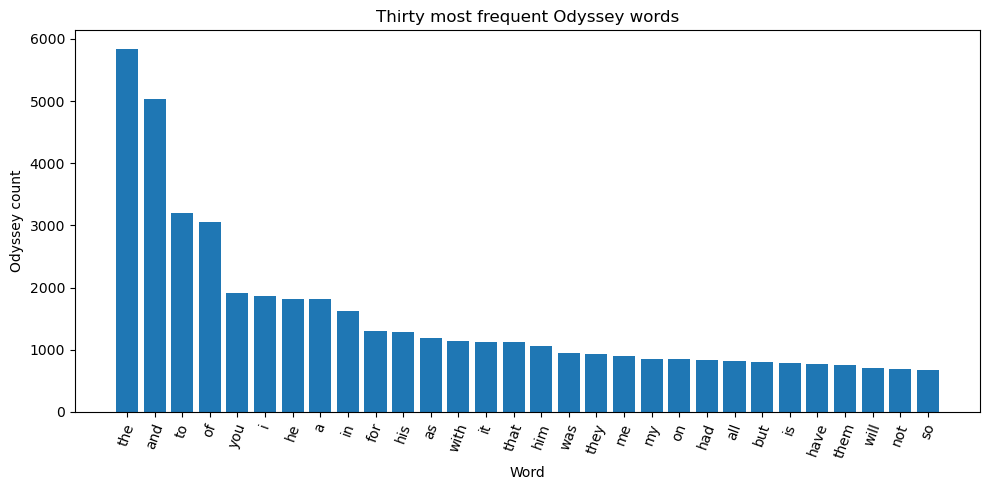

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW7.2\result images\hw7_2\task2_top_odyssey_unigrams.png


In [7]:
plot_table = (
    unigram_table[
        unigram_table[
            "word"
        ] != "</s>"
    ]
    .head(30)
)

plt.figure(figsize=(10, 5))

plt.bar(
    plot_table["word"],
    plot_table["count"],
)

plt.xlabel("Word")
plt.ylabel("Odyssey count")
plt.title(
    "Thirty most frequent Odyssey words"
)
plt.xticks(rotation=70)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task2_top_odyssey_unigrams.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 2 Conclusion

The target corpus has now been converted into a reproducible statistical language model containing unigram, bigram, and trigram counts.

Task 3 will generate from the same base model in two modes:

- unconditioned;
- Marcus-theme conditioned.

The only difference between those modes will be the predeclared theme-word probability bias.